# LeafNet on Colab — stoma detection and pavement-cell segmentation of one bright-field Arabidopsis epidermis image

**Paper:** Ching Chan, *"No more manual counting: LeafNet quantifies the leaf surface"*, The Plant Cell 34(4):1147–1148 (2022), doi:[10.1093/plcell/koac022](https://doi.org/10.1093/plcell/koac022) (PMCID PMC8972254). This is a commentary introducing the LeafNet toolkit; the tool itself was published by Shaopeng Li, Yu Zhou et al. (doi:10.1093/plcell/koac021).

**Author code executed:** [zhouyulab/leafnet](https://github.com/zhouyulab/leafnet) @ `6ef237d8fd313e1217f784ba8e45864e85f4b75a` (v1.0.1), run **unmodified** inside the author-pinned Python 3.6 environment recreated below.

**Scope (one minimal example):** segment the repository-bundled bright-field *Arabidopsis thaliana* leaf epidermis image `sample.png` with the author's `leafnet-cli` in `ALL` output mode: StomaNet stomata detection, LeafSeg pavement-cell segmentation, annotated/preview images, and morphological statistics. This is NOT a reproduction of any dataset-level benchmark from the research article.

**Provenance / AI note:** this notebook's orchestration was AI-authored for reproduction; the scientific code executed is the authors' own, byte-verified against git blob hashes from the pinned commit.

**日本語要約:** Li et al. の LeafNet（気孔検出 StomaNet + 表皮細胞分割 LeafSeg）を、著者 pinned リポジトリのバンドルサンプル `sample.png` 1 枚に対して、著者指定の Python 3.6 環境を Colab 内に再現してそのまま実行します。所要 10–20 分、ダウンロード約 400 MB。

## Runtime selection — CPU only / 実行環境は CPU

LeafNet 1.0.1 pins `tensorflow==1.13.1` (`requirements.txt`). The CPU wheel is faithful here and the GPU variant would need CUDA 10.0 + cuDNN 7.4, which is not a faithful setup on a current Colab T4 image; the README lists GPU as *optional* and one ~2 MB image needs no GPU. **Select Runtime → Change runtime type → CPU**, then *Run all*.

**Expected:** ~10–20 min total (miniforge + a Python 3.6 env ~6–10 min, pip wheels ~200 MB, repo sparse checkout ~16 MB, inference ~1–5 min on a standard Colab CPU VM with >4 GB RAM as the README requires). **日本語:** GPU は不要です。CPU ランタイムで Run all してください。

In [ ]:
import platform, os, shutil, sys
print("Colab default kernel Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("Working dir:", os.getcwd())
print("Disk free on /content (GB):", round(shutil.disk_usage("/content").free / 1e9, 1))

Colab default kernel Python: 3.13.16
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
Working dir: /content
Disk free on /content (GB): 220.5


## 1. Pinned partial clone of the author repository / 著者リポジトリの部分クローン

Fetch only what the demo needs (`leafnet/` package incl. shipped StomaNet weights and precompiled Linux `.so` plugins, `sample.png`, `requirements.txt`) from the exact author commit `6ef237d8fd313e1217f784ba8e45864e85f4b75a` using a blob-filtered, sparse clone **inside Colab**. The checked-out commit is asserted against the pin.

**日本語:** blob フィルタ + sparse checkout で必要ファイルのみ取得し、コミット固定を検証します。

In [ ]:
%%bash
set -e
cd /content
rm -rf leafnet
git clone --filter=blob:none --no-checkout --quiet https://github.com/zhouyulab/leafnet.git leafnet
cd leafnet
git sparse-checkout set leafnet sample.png requirements.txt
git checkout --quiet 6ef237d8fd313e1217f784ba8e45864e85f4b75a
echo "checked out: $(git rev-parse HEAD)"
test "$(git rev-parse HEAD)" = "6ef237d8fd313e1217f784ba8e45864e85f4b75a" || { echo "PIN MISMATCH"; exit 1; }
ls leafnet/leafnet_libs/stoma_detector/models/ | head

checked out: 6ef237d8fd313e1217f784ba8e45864e85f4b75a
__init__.py
None.model
None.res
StomaNetConfocal.model
StomaNetConfocal.res
StomaNet.model
StomaNet.res
StomaNetUniversal.model
StomaNetUniversal.res


## 2. Byte-level verification of inputs, weights and plugins / バイト検証

Verify the downloaded bytes against the git blob SHA-1s recorded from the pinned tree (`sources/pinned_blob_hashes.json` in the authoring run), check the PNG signature of the sample input, the ELF signatures of the two bundled Linux C++ plugins (LeafSeg EDT merge + GEGL denoiser, both loaded via `ctypes` by the author code), and print the author-shipped model metadata `StomaNet.res` (model resolution and DBS scale key).

**日本語:** git blob SHA-1、PNG/ELF シグネチャ、モデル付属メタデータを検証します。

In [ ]:
import subprocess
repo = "/content/leafnet"
expected = {
  "sample.png": "346f802b3918343118ca85683c61809f6ccad990",
  "leafnet/leafnet_libs/stoma_detector/models/StomaNet.model": "cfe472a266178f65a5334a2526a610c8dd61b872",
  "leafnet/leafnet_libs/stoma_detector/models/StomaNet.res": "490c8cfb9384d9e9979683e1e8b87dbdf7a6a9d8",
  "leafnet/leafnet_libs/cell_divider/LeafSeg/edt_model.so": "b495052ce0c500f0fc98cde8d4a749e088e9c97e",
  "leafnet/leafnet_libs/image_denoiser/PeeledDenoiser/gegl_denoise.so": "237869cca0a14874d7860617f9b7d78a78d0eb0b",
  "requirements.txt": "bcc1f3a02c605e9c419344c682e7ef8338eb8267",
}
ok = True
for rel, sha in expected.items():
    got = subprocess.run(["git", "hash-object", rel], cwd=repo, capture_output=True, text=True, check=True).stdout.strip()
    status = "OK" if got == sha else "MISMATCH"
    ok &= got == sha
    print(f"{status:9s} {rel}")
assert ok, "Git blob hash verification failed"
with open(repo + "/sample.png", "rb") as f:
    assert f.read(8) == bytes.fromhex("89504e470d0a1a0a"), "sample.png is not a valid PNG"
print("sample.png: valid PNG signature")
for so in ["leafnet/leafnet_libs/cell_divider/LeafSeg/edt_model.so",
           "leafnet/leafnet_libs/image_denoiser/PeeledDenoiser/gegl_denoise.so"]:
    with open(repo + "/" + so, "rb") as f:
        assert f.read(4) == b"\x7fELF", so + " is not an ELF object"
    print("ELF OK:", so)
print("--- StomaNet.res (author-shipped model metadata) ---")
print(open(repo + "/leafnet/leafnet_libs/stoma_detector/models/StomaNet.res").read().strip())

OK        sample.png


OK        leafnet/leafnet_libs/stoma_detector/models/StomaNet.model
OK        leafnet/leafnet_libs/stoma_detector/models/StomaNet.res
OK        leafnet/leafnet_libs/cell_divider/LeafSeg/edt_model.so
OK        leafnet/leafnet_libs/image_denoiser/PeeledDenoiser/gegl_denoise.so
OK        requirements.txt
sample.png: valid PNG signature
ELF OK: leafnet/leafnet_libs/cell_divider/LeafSeg/edt_model.so
ELF OK: leafnet/leafnet_libs/image_denoiser/PeeledDenoiser/gegl_denoise.so
--- StomaNet.res (author-shipped model metadata) ---
2.17
NORMAL_DBS


## 3. Recreate the author-pinned Python 3.6 environment / 著者固定環境の再現

`requirements.txt` pins the exact 2022-era stack (tensorflow 1.13.1, numpy 1.18, opencv 4.1.2, Pillow 7.0, scikit-image 0.16, scikit-learn 0.22, scipy 1.4, h5py 2.10, matplotlib 3.1). The author code uses APIs removed from modern libraries (`PIL.Image.ANTIALIAS`, skimage `selem=`, `scipy.ndimage.filters`, `np.float`), so the faithful route is to recreate the author environment with Miniforge (conda-forge) inside Colab and run their code unmodified. This is the longest step (~6–10 min).

**日本語:** Miniforge で Python 3.6 環境を作り、著者 pinned の依存関係をそのまま入れます（最長ステップ）。

In [ ]:
%%bash
set -e
set -o pipefail
cd /content
if [ ! -x /content/miniforge/bin/conda ]; then
  wget -q https://github.com/conda-forge/miniforge/releases/latest/download/Miniforge3-Linux-x86_64.sh -O miniforge.sh
  bash miniforge.sh -b -p /content/miniforge > /dev/null
fi
/content/miniforge/bin/conda create -y -n leafnet python=3.6 pip 2>&1 | tail -8
/content/miniforge/envs/leafnet/bin/python --version

# To activate this environment, use
#
#     $ conda activate leafnet
#
# To deactivate an active environment, use
#
#     $ conda deactivate

Python 3.6.15


warning  libmamba Security Warning: This transaction includes executing package scripts (pre/post-link/unlink) if present. These scripts can contain arbitrary code. Please ensure you trust the package sources.


## 4. Install the author's pinned dependencies / pinned 依存のインストール

The author `requirements.txt` is printed verbatim above the install. Under PEP 440 its `opencv-python==4.1.2` pin has no exact match (the 4.1.2 series is 4.1.2.30), so the notebook installs the **exact versions from the authors' own conda recipe** (`conda-recipe/meta.yaml` v1.0.1 — their recommended install path), which pins h5py 2.10.0, matplotlib 3.1.2, numpy 1.18.1, opencv 4.1.2.30, Pillow 7.0.0, scikit-image 0.16.2, scikit-learn 0.22.1, scipy 1.4.1, tensorflow 1.13.1 — the same stack `requirements.txt` describes. `opencv-python` 4.1.2.30 wheels link `libGL.so.1`; if the Colab VM lacks it we install that system library explicitly before importing.

**日本語:** 著者の conda レシピ（推奨インストール経路）と同じバージョンを導入します（requirements.txt の `==4.1.2` は PEP 440 の厳密一致では解決不能のため）。libGL が無ければ追加します。

In [ ]:
%%bash
set -e
set -o pipefail
cd /content/leafnet
echo "--- requirements.txt (author-pinned, verbatim) ---"
cat requirements.txt
cat > /content/req_colab.txt <<'EOF'
# Exact versions from the authors' conda recipe (conda-recipe/meta.yaml, leafnet 1.0.1),
# the recommended install path; requirements.txt pins the same stack but
# opencv-python==4.1.2 is not a resolvable PEP 440 pin (series: 4.1.2.30).
h5py==2.10.0
matplotlib==3.1.2
numpy==1.18.1
opencv-python==4.1.2.30
Pillow==7.0.0
scikit-image==0.16.2
scikit-learn==0.22.1
scipy==1.4.1
tensorflow==1.13.1
EOF
/content/miniforge/envs/leafnet/bin/pip install --no-input -r /content/req_colab.txt 2>&1 | tail -6
if ! /content/miniforge/envs/leafnet/bin/python -c "import cv2" 2>/dev/null; then
  echo "installing libGL for opencv ..."
  apt-get install -yqq libgl1 libglib2.0-0 > /dev/null
fi
/content/miniforge/envs/leafnet/bin/python -c "import tensorflow as tf, numpy, cv2, skimage, sklearn, scipy, h5py, PIL; print('tensorflow', tf.__version__, '| numpy', numpy.__version__, '| opencv', cv2.__version__)" 

--- requirements.txt (author-pinned, verbatim) ---
h5py==2.10
matplotlib==3.1
numpy==1.18
opencv-python==4.1.2
Pillow==7.0
scikit-image==0.16
scikit-learn==0.22
scipy==1.4
tensorflow==1.13  Created wheel for termcolor: filename=termcolor-1.1.0-py3-none-any.whl size=4848 sha256=6b8e6c137c086ee9b4104a9730008528311d912ce29daa7a4ac66667478398a9
  Stored in directory: /root/.cache/pip/wheels/93/2a/eb/e58dbcbc963549ee4f065ff80a59f274cc7210b6eab962acdc
Successfully built termcolor
tensorflow 1.13.1 | numpy 1.18.1 | opencv 4.1.2


/content/miniforge/envs/leafnet/lib/python3.6/site-packages/tensorflow/python/framework/dtypes.py:526: FutureWarning: Passing (type, 1) or '1type' as a synonym of type is deprecated; in a future version of numpy, it will be understood as (type, (1,)) / '(1,)type'.
  _np_qint8 = np.dtype([("qint8", np.int8, 1)])
/content/miniforge/envs/leafnet/lib/python3.6/site-packages/tensorflow/python/framework/dtypes.py:527: FutureWarning: Passing (type, 1) or '1type' as a synonym of type is deprecated; in a future version of numpy, it will be understood as (type, (1,)) / '(1,)type'.
  _np_quint8 = np.dtype([("quint8", np.uint8, 1)])
/content/miniforge/envs/leafnet/lib/python3.6/site-packages/tensorflow/python/framework/dtypes.py:528: FutureWarning: Passing (type, 1) or '1type' as a synonym of type is deprecated; in a future version of numpy, it will be understood as (type, (1,)) / '(1,)type'.
  _np_qint16 = np.dtype([("qint16", np.int16, 1)])
/content/miniforge/envs/leafnet/lib/python3.6/site-pack

## 5. Load the shipped StomaNet checkpoint / StomaNet 重みのロード確認

The StomaNet weights ship with the package (`leafnet/leafnet_libs/stoma_detector/models/StomaNet.model`, a Keras model saved by the authors). Load it exactly as `stoma_detector.py` does and print its input/output shapes (the detector tiles the image into 186×186 inputs and reads 186×186 heatmaps back).

**日本語:** 同梱の StomaNet.model を著者コードと同じ方法で読み込み、入出力形状を確認します。

In [ ]:
%%bash
cd /content/leafnet
/content/miniforge/envs/leafnet/bin/python - <<'EOF'
import os
os.environ.setdefault("MPLBACKEND", "Agg")
from tensorflow.keras.models import load_model
m = load_model("leafnet/leafnet_libs/stoma_detector/models/StomaNet.model")
print("StomaNet loaded OK. input:", m.input_shape, "-> output:", m.output_shape)
EOF

StomaNet loaded OK. input: (None, 186, 186, 1) -> output: (None, 104, 104, 2)


/content/miniforge/envs/leafnet/lib/python3.6/site-packages/tensorflow/python/framework/dtypes.py:526: FutureWarning: Passing (type, 1) or '1type' as a synonym of type is deprecated; in a future version of numpy, it will be understood as (type, (1,)) / '(1,)type'.
  _np_qint8 = np.dtype([("qint8", np.int8, 1)])
/content/miniforge/envs/leafnet/lib/python3.6/site-packages/tensorflow/python/framework/dtypes.py:527: FutureWarning: Passing (type, 1) or '1type' as a synonym of type is deprecated; in a future version of numpy, it will be understood as (type, (1,)) / '(1,)type'.
  _np_quint8 = np.dtype([("quint8", np.uint8, 1)])
/content/miniforge/envs/leafnet/lib/python3.6/site-packages/tensorflow/python/framework/dtypes.py:528: FutureWarning: Passing (type, 1) or '1type' as a synonym of type is deprecated; in a future version of numpy, it will be understood as (type, (1,)) / '(1,)type'.
  _np_qint16 = np.dtype([("qint16", np.int16, 1)])
/content/miniforge/envs/leafnet/lib/python3.6/site-pack

## 6. Input preview — the bundled author sample / 入力プレビュー

`sample.png` is the bright-field *Arabidopsis* leaf epidermal peel that the authors bundle in the repository and recommend as an example (README: "Users could take sample.png in this repo for a good example", 200× magnification suggested). Display it before analysis; its size and resolution are printed from the actual file.

**日本語:** 著者提供の明視野 Arabidopsis 表皮剥離サンプル `sample.png` を表示します。

sample.png (w, h): (1392, 1040) | mode: RGBA


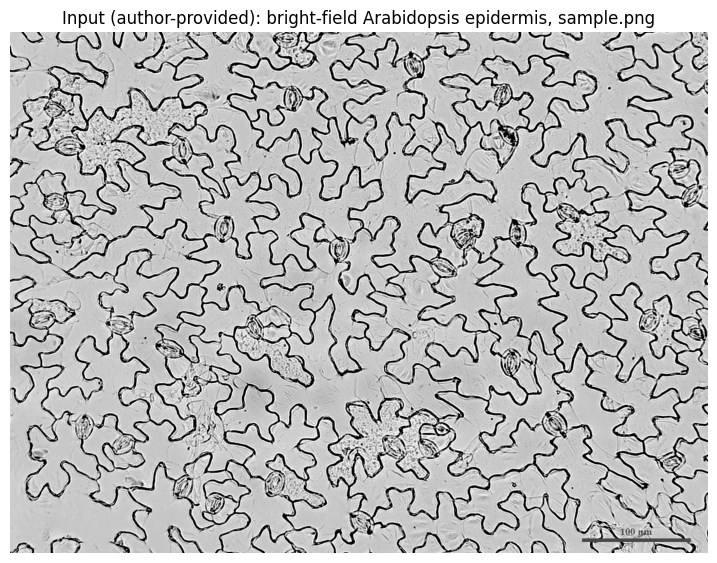

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
img = Image.open("/content/leafnet/sample.png")
print("sample.png (w, h):", img.size, "| mode:", img.mode)
plt.figure(figsize=(9, 7))
plt.imshow(img.convert("L"), cmap="gray")
plt.title("Input (author-provided): bright-field Arabidopsis epidermis, sample.png")
plt.axis("off")
plt.show()

## 7. Run the author's LeafNet CLI / LeafNet CLI の実行

Run `python -m leafnet.leafnet_cli` **unmodified** with the README defaults for this image class (`--res 2.17` px/μm, bright background, PeeledDenoiser, StomaNet, LeafSeg; thresholds --sd_ts 40, --cd_ts 60, --min_cs 85 are CLI defaults). Output mode `ALL` writes `sample.png_graph.png` (colored cell overlay), `sample.png_anno.png` (green cell walls, blue stomata) and `sample.png_statistic.txt` (morphological statistics).

**日本語:** 著者の CLI を未改変のまま README 既定設定で実行し、プレビュー/アノテーション/統計を出力します。

In [ ]:
%%bash
set -e
cd /content/leafnet
export MPLBACKEND=Agg
rm -rf /content/leafnet_out
time /content/miniforge/envs/leafnet/bin/python -m leafnet.leafnet_cli \
  -i sample.png -m ALL -o /content/leafnet_out \
  --res 2.17 --bg Bright --dn PeeledDenoiser --sd StomaNet --cd LeafSeg
echo "--- output files ---"
ls -la /content/leafnet_out

--- output files ---
total 2140
drwxr-xr-x 2 root root    4096 Oct 27 13:32 .
drwxr-xr-x 1 root root    4096 Oct 27 13:28 ..
-rw-r--r-- 1 root root   78142 Oct 27 13:32 sample.png_anno.png
-rw-r--r-- 1 root root 2093651 Oct 27 13:32 sample.png_graph.png
-rw-r--r-- 1 root root    2258 Oct 27 13:32 sample.png_statistic.txt


/content/miniforge/envs/leafnet/lib/python3.6/site-packages/tensorflow/python/framework/dtypes.py:526: FutureWarning: Passing (type, 1) or '1type' as a synonym of type is deprecated; in a future version of numpy, it will be understood as (type, (1,)) / '(1,)type'.
  _np_qint8 = np.dtype([("qint8", np.int8, 1)])
/content/miniforge/envs/leafnet/lib/python3.6/site-packages/tensorflow/python/framework/dtypes.py:527: FutureWarning: Passing (type, 1) or '1type' as a synonym of type is deprecated; in a future version of numpy, it will be understood as (type, (1,)) / '(1,)type'.
  _np_quint8 = np.dtype([("quint8", np.uint8, 1)])
/content/miniforge/envs/leafnet/lib/python3.6/site-packages/tensorflow/python/framework/dtypes.py:528: FutureWarning: Passing (type, 1) or '1type' as a synonym of type is deprecated; in a future version of numpy, it will be understood as (type, (1,)) / '(1,)type'.
  _np_qint16 = np.dtype([("qint16", np.int16, 1)])
/content/miniforge/envs/leafnet/lib/python3.6/site-pack

## 8. Results — annotation and preview overlays / 結果の表示

Side-by-side: the original input, the author pipeline's annotation (`_anno.png`: green = cell walls, blue = stomata), and the preview overlay (`_graph.png`: each segmented cell colored). These are the actual files written by the author CLI in this run.

**日本語:** 入力、アノテーション（壁＝緑、気孔＝青）、セルごとの色分けプレビューを並べて表示します。

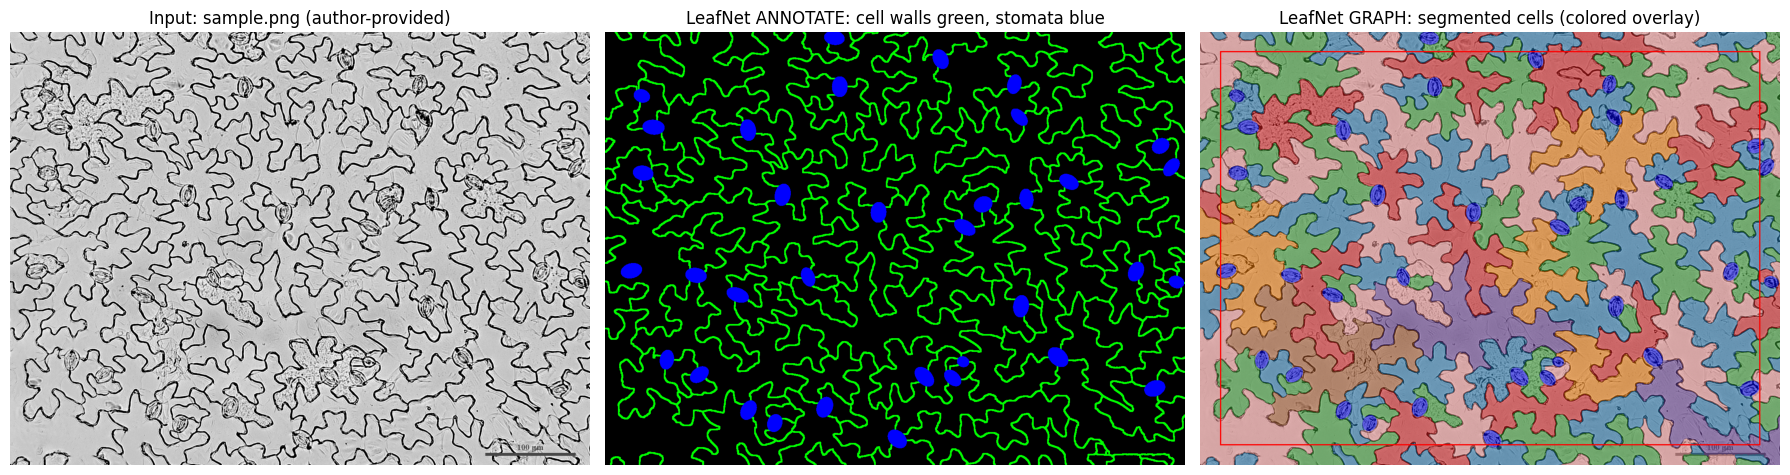

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
inp = Image.open("/content/leafnet/sample.png").convert("L")
anno = Image.open("/content/leafnet_out/sample.png_anno.png")
graph = Image.open("/content/leafnet_out/sample.png_graph.png")
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(inp, cmap="gray"); axes[0].set_title("Input: sample.png (author-provided)")
axes[1].imshow(anno); axes[1].set_title("LeafNet ANNOTATE: cell walls green, stomata blue")
axes[2].imshow(graph); axes[2].set_title("LeafNet GRAPH: segmented cells (colored overlay)")
for a in axes:
    a.axis("off")
plt.tight_layout()
plt.show()

## 9. Morphological statistics / 形態統計

Parse `sample.png_statistic.txt`, written by the authors' `generate_statistics` (all areas in µm² at the model resolution 2.17 px/µm; cell counts are border-adjusted; border-touching cells/stomata are excluded from size lists). Stoma density per mm² and medians are computed **in this notebook** from the author CLI output. A cell-size histogram is added as a visualization created for this notebook, not an author figure. CSV exports are written to `/content/leafnet_out/`.

**日本語:** 著者 CLI の統計出力を解析して表とヒストグラムにし、CSV を書き出します（密度・中央値はこのノートブックでの集計）。

,Metric (units),Value (author CLI output / this-notebook aggregation)
0,Effective image area (μm²),257911.614177
1,Stoma count (within effective area),32.000000
2,Pavement cell count (border-adjusted),77.500000
3,"Stoma density, per mm² (computed in this noteb...",124.100000
4,Median stoma size (μm²),260.900000
5,Median stoma aspect ratio (computed in this no...,1.380000
6,Median pavement cell size (μm²),2257.000000


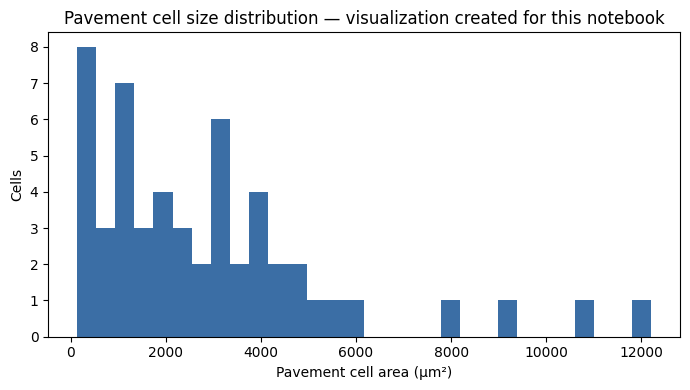

CSV exports: /content/leafnet_out/sample_cell_sizes.csv, /content/leafnet_out/sample_stomata.csv
Provenance: github.com/zhouyulab/leafnet @ 6ef237d8fd313e1217f784ba8e45864e85f4b75a, author-pinned requirements.txt


In [ ]:
import ast
import pandas as pd
import matplotlib.pyplot as plt

stat = {}
for line in open("/content/leafnet_out/sample.png_statistic.txt"):
    k, _, v = line.strip().partition(":")
    stat[k] = v

stoma_sizes = ast.literal_eval(stat["stoma_sizes"])
stoma_aspects = ast.literal_eval(stat["stoma_aspects"])
cell_sizes = ast.literal_eval(stat["cell_sizes"])
eff_area_um2 = float(stat["image_effective_size"])
stoma_count = int(stat["stoma_count"])
cell_count = float(stat["cell_count"])

rows = [
    ("Effective image area (μm²)", eff_area_um2),
    ("Stoma count (within effective area)", stoma_count),
    ("Pavement cell count (border-adjusted)", cell_count),
    ("Stoma density, per mm² (computed in this notebook)", round(stoma_count * 1e6 / eff_area_um2, 1)),
    ("Median stoma size (μm²)", round(sorted(stoma_sizes)[len(stoma_sizes)//2], 1) if stoma_sizes else float("nan")),
    ("Median stoma aspect ratio (computed in this notebook)", round(sorted(stoma_aspects)[len(stoma_aspects)//2], 2) if stoma_aspects else float("nan")),
    ("Median pavement cell size (μm²)", round(sorted(cell_sizes)[len(cell_sizes)//2], 1) if cell_sizes else float("nan")),
]
display(pd.DataFrame(rows, columns=["Metric (units)", "Value (author CLI output / this-notebook aggregation)"]))

plt.figure(figsize=(7, 4))
plt.hist(cell_sizes, bins=30, color="#3b6ea5")
plt.xlabel("Pavement cell area (μm²)")
plt.ylabel("Cells")
plt.title("Pavement cell size distribution — visualization created for this notebook")
plt.tight_layout()
plt.show()

pd.DataFrame({"cell_size_um2": cell_sizes}).to_csv("/content/leafnet_out/sample_cell_sizes.csv", index=False)
pd.DataFrame({"stoma_size_um2": stoma_sizes, "stoma_aspect": stoma_aspects}).to_csv("/content/leafnet_out/sample_stomata.csv", index=False)
print("CSV exports: /content/leafnet_out/sample_cell_sizes.csv, /content/leafnet_out/sample_stomata.csv")
print("Provenance: github.com/zhouyulab/leafnet @ " + "6ef237d8fd313e1217f784ba8e45864e85f4b75a" + ", author-pinned requirements.txt")

## Interpretation, limitations, references / 解釈と限界

**What this demonstrates.** The author-bundled bright-field epidermis image `sample.png` was segmented end-to-end with the authors' LeafNet 1.0.1 (StomaNet stomata detection → LeafSeg pavement-cell segmentation) exactly as their README prescribes, producing the annotation, preview and statistics outputs. This reproduces the pipeline the commentary describes (stomata detected by a CNN and masked out, pavement cells segmented by region merging/watershed, then dozens of features quantified).

**Limitations.** One image; no claim of the dataset-level performance reported in the Li et al. research article (koac021). The GPU path was not exercised (TF 1.13 needs CUDA 10; not faithful on modern Colab). The commentary itself (koac022) contains no methods; all quantitative behavior comes from the pinned author code. The repository ships no LICENSE file (MIT is declared only in the conda recipe metadata) — reuse beyond this demonstration should confirm licensing with the authors (Shaopeng Li / Yu Zhou, Wuhan University).

**Validation record.** Executed on a fresh Google Colab **CPU** runtime (standard VM); all verification cells passed (commit pin, git blob SHA-1s, PNG/ELF signatures, model load). See the accompanying report for measured timings.

**References / 日本語の参照:** Chan 2022 Plant Cell 34(4):1147–1148 (commentary, koac022); Li et al. 2022 Plant Cell (koac021); zhouyulab/leafnet @ 6ef237d8fd313e1217f784ba8e45864e85f4b75a; leafnet.whu.edu.cn. LeafNet の実体は Li et al. の研究論文であり、このノートブックは解説論文が紹介するツールの最小デモです。